# Лабораторная работа №3: оптимизация гиперпараметров

**Задача:** берём классификацию из лабораторной №2 (Титаник, выжил пассажир или нет).
**Модель:** Gradient Boosting (градиентный бустинг).
**Метрика:** F1 для класса «выжил», как в лабе 2.

**Гиперпараметры** — это настройки модели, которые мы задаём **до** обучения (сколько деревьев, какой глубины и т.д.).
Сама модель их не учит. Задача — найти хорошие настройки честно, не подглядывая в тестовую выборку.

## 0. Импорты

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint, loguniform

from sklearn.model_selection import (train_test_split, StratifiedKFold, cross_val_score,
                                     GridSearchCV, RandomizedSearchCV, validation_curve)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import f1_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

## 1. Данные (как в лабе 2)

Берём те же признаки и то же разбиение train/test (`random_state=42`, `stratify`).
Масштабирование не делаем: бустинг строит деревья, а деревьям масштаб признаков не важен.

In [2]:
df = pd.read_csv("../classification/data/Titanic-Dataset.csv")
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

num_features = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize"]
cat_features = ["Sex", "Embarked"]
X = df[num_features + cat_features]
y = df["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]), cat_features),
])

def make_model(**params):
    """Предобработка + бустинг с заданными гиперпараметрами."""
    return Pipeline([("prep", preprocess),
                     ("model", GradientBoostingClassifier(random_state=RANDOM_STATE, **params))])

print("train:", X_train.shape, " test:", X_test.shape)

train: (712, 8)  test: (179, 8)

## 2. Кросс-валидация

**Как работает:** train делим на 5 частей (folds). 5 раз обучаем модель на 4 частях и проверяем на оставшейся.
Получаем 5 оценок и берём среднее.

**Почему 5 folds:** данных мало. При 5 folds проверочные части достаточно большие, чтобы оценка не была слишком шумной,
и модель учится на большей части train. При 10 folds проверочные части были бы вдвое меньше, а работало бы всё вдвое дольше.
`StratifiedKFold` сохраняет долю выживших в каждой части.

**Ответы на вопросы:**
- *Зачем нужна кросс-валидация?* Чтобы оценить качество модели по train, не трогая test. Каждый объект train один раз побывает в проверке.
- *Почему одного разбиения мало?* Результат на одной небольшой проверочной части сильно зависит от того, какие люди туда попали. Можно выбрать параметры, которые просто «повезло» угадать на этой части. Среднее по 5 частям надёжнее.
- *Что будет, если много раз выбирать параметры по test?* Мы подгоним модель под test. Результат на test станет завышенным, и мы не узнаем, как модель работает на новых данных. Test перестанет быть «экзаменом».

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 3. Baseline: модель с параметрами по умолчанию

In [4]:
baseline = make_model()   # n_estimators=100, learning_rate=0.1, max_depth=3
print(baseline.named_steps["model"].get_params()["n_estimators"],
      baseline.named_steps["model"].get_params()["learning_rate"],
      baseline.named_steps["model"].get_params()["max_depth"])

baseline_scores = cross_val_score(baseline, X_train, y_train, cv=cv, scoring="f1")
print("F1 по folds:", baseline_scores.round(3))
print(f"Baseline CV F1 = {baseline_scores.mean():.4f} ± {baseline_scores.std():.4f}")

100 0.1 3
F1 по folds: [0.811 0.724 0.774 0.704 0.742]
Baseline CV F1 = 0.7511 ± 0.0380

**Вывод.** Модель по умолчанию уже даёт неплохой F1 на кросс-валидации. Это точка отсчёта: подбор параметров должен её улучшить.

## 4. Выбранные гиперпараметры

| Параметр | Смысл | Диапазон | Что будет при изменении |
|---|---|---|---|
| `n_estimators` | сколько деревьев строит бустинг | 50 – 500 | мало деревьев — модель недоучится; слишком много — начнёт подгоняться под шум |
| `learning_rate` | насколько сильно каждое новое дерево исправляет ошибки предыдущих | 0.01 – 0.3 | маленький — учится медленно (нужно больше деревьев), большой — быстро, но легко переобучается |
| `max_depth` | глубина каждого дерева | 1 – 5 | маленькая — простые правила (недообучение), большая — сложные правила, запоминание (переобучение) |

`n_estimators` и `learning_rate` связаны: чем меньше шаг, тем больше нужно деревьев.

## 5. Grid Search (полный перебор по сетке)

In [5]:
param_grid = {
    "model__n_estimators": [50, 100, 200, 400],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.3],
    "model__max_depth": [1, 2, 3, 4, 5],
}
n_comb = np.prod([len(v) for v in param_grid.values()])
print("Комбинаций в сетке:", n_comb, "| обучений модели:", n_comb * cv.get_n_splits())

grid = GridSearchCV(make_model(), param_grid, cv=cv, scoring="f1", n_jobs=-1, return_train_score=True)
start = time.time()
grid.fit(X_train, y_train)          # подбор только на train
grid_time = time.time() - start

print("Лучшие параметры:", grid.best_params_)
print(f"CV F1 = {grid.best_score_:.4f}")
print(f"Время: {grid_time:.1f} с")

Комбинаций в сетке: 80 | обучений модели: 400
Лучшие параметры: {'model__learning_rate': 0.1, 'model__max_depth': 3, 'model__n_estimators': 200}
CV F1 = 0.7645
Время: 8.0 с

In [6]:
# Топ-5 комбинаций
cols = ["param_model__n_estimators", "param_model__learning_rate", "param_model__max_depth",
        "mean_test_score", "std_test_score"]
pd.DataFrame(grid.cv_results_)[cols].sort_values("mean_test_score", ascending=False).head().round(4)

,param_model__n_estimators,param_model__learning_rate,param_model__max_depth,mean_test_score,std_test_score
50,200,0.10,3,0.7645,0.0163
35,400,0.05,4,0.7629,0.0165
31,400,0.05,3,0.7628,0.0210
72,50,0.30,4,0.7622,0.0298
53,100,0.10,4,0.7604,0.0280


**Вывод.** Перебрали все комбинации из сетки. Лучшая комбинация немного лучше baseline на кросс-валидации.
Видно, что у первых мест в топе очень близкие результаты: разница меньше, чем разброс между folds.

## 6. Random Search (случайный поиск)

In [7]:
param_dist = {
    "model__n_estimators": randint(50, 501),          # любое целое от 50 до 500
    "model__learning_rate": loguniform(0.01, 0.3),    # чаще маленькие значения, реже большие
    "model__max_depth": randint(1, 6),                # от 1 до 5
}
rand = RandomizedSearchCV(make_model(), param_dist, n_iter=40, cv=cv, scoring="f1",
                          n_jobs=-1, random_state=RANDOM_STATE, return_train_score=True)
start = time.time()
rand.fit(X_train, y_train)
rand_time = time.time() - start

print("Лучшие параметры:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in rand.best_params_.items()})
print(f"CV F1 = {rand.best_score_:.4f}")
print(f"Время: {rand_time:.1f} с")

Лучшие параметры: {'model__learning_rate': np.float64(0.0916), 'model__max_depth': 4, 'model__n_estimators': 184}
CV F1 = 0.7660
Время: 4.1 с

In [8]:
compare = pd.DataFrame({
    "Комбинаций": [n_comb, rand.n_iter],
    "Лучший CV F1": [grid.best_score_, rand.best_score_],
    "Время, с": [grid_time, rand_time],
}, index=["Grid Search", "Random Search"])
compare.round(4)

,Комбинаций,Лучший CV F1,"Время, с"
Grid Search,80,0.7645,7.9861
Random Search,40,0.7660,4.0656


**Вывод.**
- Random Search проверил вдвое меньше комбинаций и работал быстрее, а качество нашёл такое же (разница — на уровне шума).
- Random Search берёт любые значения из диапазона (например, 137 деревьев или шаг 0.068), а не только те, что мы вписали в сетку.

**Когда случайный поиск лучше полного перебора:**
- когда параметров много — сетка растёт очень быстро (5 параметров по 5 значений = 3125 комбинаций);
- когда важны только 1–2 параметра из многих: случайный поиск пробует больше разных значений каждого из них;
- когда времени мало: можно задать бюджет `n_iter` заранее.

## 7. Влияние гиперпараметров на качество

In [9]:
def plot_curve(param, values, log=False, **fixed):
    """F1 на train и на кросс-валидации в зависимости от одного параметра."""
    train_sc, val_sc = validation_curve(make_model(**fixed), X_train, y_train,
                                        param_name="model__" + param, param_range=values,
                                        cv=cv, scoring="f1", n_jobs=-1)
    plt.figure(figsize=(7, 4))
    plt.plot(values, train_sc.mean(axis=1), "o-", label="train")
    plt.plot(values, val_sc.mean(axis=1), "o-", label="кросс-валидация")
    plt.fill_between(values, val_sc.mean(axis=1) - val_sc.std(axis=1),
                     val_sc.mean(axis=1) + val_sc.std(axis=1), alpha=0.2)
    if log:
        plt.xscale("log")
    plt.xlabel(param); plt.ylabel("F1"); plt.title(f"Влияние {param}"); plt.legend()
    plt.show()
    return pd.DataFrame({param: values, "train": train_sc.mean(axis=1).round(3),
                         "CV": val_sc.mean(axis=1).round(3)}).set_index(param).T

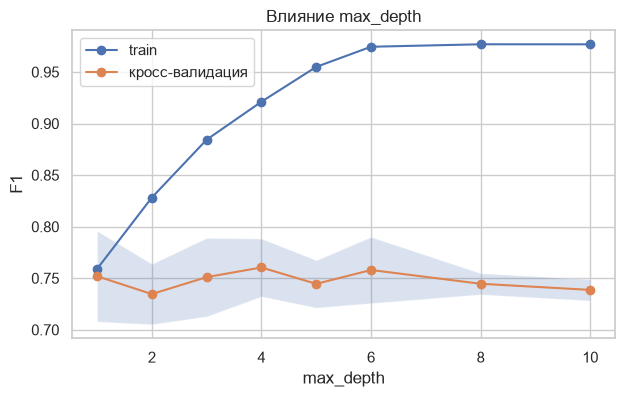

max_depth,1,2,3,4,5,6,8,10
train,0.759,0.828,0.884,0.921,0.955,0.974,0.977,0.977
CV,0.752,0.735,0.751,0.760,0.745,0.758,0.745,0.739


In [10]:
plot_curve("max_depth", [1, 2, 3, 4, 5, 6, 8, 10])

**Вывод (`max_depth`):**
- **Недообучение** — самая маленькая глубина: каждое дерево задаёт всего один вопрос (например, «мужчина или женщина?»). Модель слишком простая.
- **Разумная сложность** — средняя глубина: на CV лучший результат, а разрыв с train ещё небольшой.
- **Переобучение** — большая глубина: на train почти идеально, а на CV лучше не становится. Модель запоминает пассажиров.
- CV-кривая немного прыгает вверх-вниз — это шум из-за маленьких данных, поэтому смотрим на общую картину, а не на каждую точку.

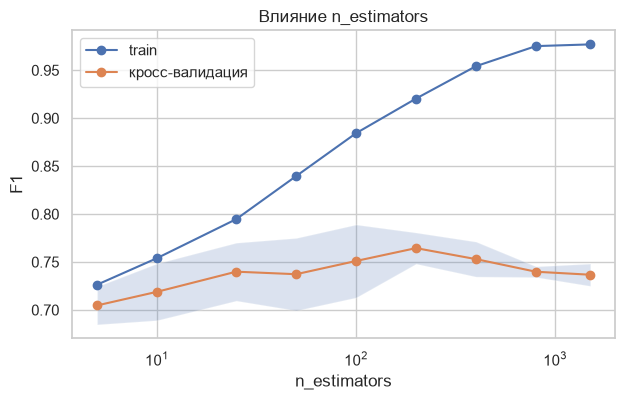

n_estimators,5,10,25,50,100,200,400,800,1500
train,0.726,0.754,0.795,0.840,0.884,0.920,0.954,0.975,0.977
CV,0.705,0.719,0.740,0.737,0.751,0.764,0.753,0.740,0.737


In [11]:
plot_curve("n_estimators", [5, 10, 25, 50, 100, 200, 400, 800, 1500], log=True)

**Вывод (`n_estimators`):**
- **Недообучение** — мало деревьев: модель ещё не успела выучить закономерности.
- **Разумная сложность** — среднее число деревьев, CV на максимуме.
- **Переобучение** — дальше train продолжает расти, а CV стоит на месте или падает: новые деревья подгоняются под шум.

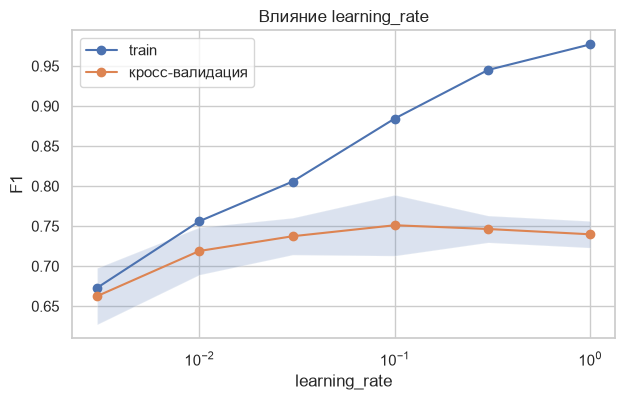

learning_rate,0.003,0.010,0.030,0.100,0.300,1.000
train,0.673,0.756,0.806,0.884,0.945,0.977
CV,0.662,0.719,0.737,0.751,0.746,0.740


In [12]:
plot_curve("learning_rate", [0.003, 0.01, 0.03, 0.1, 0.3, 1.0], log=True)

**Вывод (`learning_rate`)**:
- Очень маленький шаг — **недообучение**: за отведённое число деревьев модель не успевает научиться.
- Средний шаг — лучший результат.
- Большой шаг — **переобучение**: train растёт, CV падает, каждое дерево слишком сильно «исправляет» ошибки.

## 8. Финальная модель и проверка на test

Параметры уже выбраны по кросс-валидации. Только теперь обучаем модели на всём train и **один раз** смотрим на test.

In [13]:
final = {
    "Baseline (по умолчанию)": (make_model(), baseline_scores.mean()),
    "Grid Search": (grid.best_estimator_, grid.best_score_),
    "Random Search": (rand.best_estimator_, rand.best_score_),
}
rows = {}
for name, (model, cv_score) in final.items():
    model.fit(X_train, y_train)
    rows[name] = {"CV F1": cv_score, "Test F1": f1_score(y_test, model.predict(X_test))}
final_res = pd.DataFrame(rows).T
final_res.round(4)

,CV F1,Test F1
Baseline (по умолчанию),0.7511,0.7213
Grid Search,0.7645,0.7302
Random Search,0.7660,0.7244


**Вывод.**
- На кросс-валидации подбор дал небольшой прирост по сравнению с baseline.
- На test прирост ещё меньше, у Random Search его почти нет.
- Почему не совпадает: test маленький, и один-два пассажира уже заметно меняют F1. Такие разницы — в пределах шума.
- Кроме того, лучшая комбинация выбрана как максимум из многих попыток, поэтому её CV-оценка немного завышена «везением».
- Главное: всё решали по кросс-валидации, test использовали один раз в конце — эксперимент честный.

## 9. Анализ устойчивости

,Baseline,Grid Search,Random Search
fold 1,0.811,0.792,0.800
fold 2,0.724,0.755,0.729
fold 3,0.774,0.771,0.788
fold 4,0.704,0.759,0.782
fold 5,0.742,0.745,0.731


Среднее:
Baseline         0.7511
Grid Search      0.7645
Random Search    0.7660
dtype: float64
Разброс (std):
Baseline         0.0425
Grid Search      0.0182
Random Search    0.0336
dtype: float64

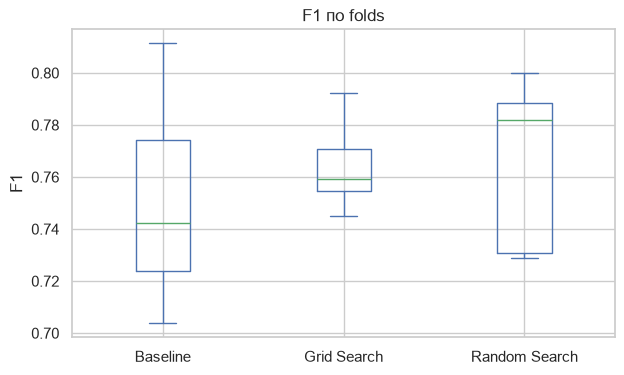

In [14]:
def fold_scores(search):
    """F1 на каждом из 5 folds для лучшей комбинации поиска."""
    i = search.best_index_
    return [search.cv_results_[f"split{k}_test_score"][i] for k in range(cv.get_n_splits())]

folds = pd.DataFrame({
    "Baseline": baseline_scores,
    "Grid Search": fold_scores(grid),
    "Random Search": fold_scores(rand),
}, index=[f"fold {k+1}" for k in range(5)])

display(folds.round(3))
print("Среднее:"); print(folds.mean().round(4))
print("Разброс (std):"); print(folds.std().round(4))

folds.plot(kind="box", figsize=(7, 4))
plt.title("F1 по folds"); plt.ylabel("F1")
plt.show()

**Вывод.**
- На разных folds F1 отличается заметно — сильнее, чем выигрыш от подбора параметров.
- Модель Grid Search не только чуть лучше в среднем, но и стабильнее всех (самый маленький разброс).
- Поэтому смотреть только на среднее мало: важно, насколько результат стабилен.
- **Почему две модели с одинаковым средним могут отличаться по устойчивости:** одна может давать 0.75 на всех folds,
  а другая — 0.65 на одном и 0.85 на другом. Среднее одинаковое, но вторая модель непредсказуемая: на новых данных
  она может сработать как хорошо, так и плохо. Обычно лучше выбрать стабильную модель.

## 10. Итоговые выводы

- Взяли задачу Титаника и Gradient Boosting. Подбирали 3 гиперпараметра: число деревьев, шаг обучения, глубину.
- Параметры выбирали только по 5-fold кросс-валидации на train. Test использовали один раз в самом конце.
- Random Search проверил вдвое меньше комбинаций, чем Grid Search, и нашёл то же качество быстрее.
- Подбор параметров дал небольшой прирост: настройки по умолчанию у бустинга уже неплохие.
- По графикам видно недообучение (маленькая глубина, мало деревьев, маленький шаг) и переобучение
  (большая глубина, большой шаг): на train качество растёт, а на кросс-валидации падает.
- Разброс F1 между folds сопоставим с выигрышем от подбора, поэтому мелкие различия между моделями — это скорее шум.